# Notebook 1: export the satellite grids

Builds the extended grid that encloses the two EPA stations, then exports the satellite
layers the inference models need over it.


## Cell 1: Open the grid


cells: 900
crs: EPSG:26986
columns: ['id', 'geometry']
bounds: [232762.52665634 898058.68525846 234668.0723502  899559.49528916]


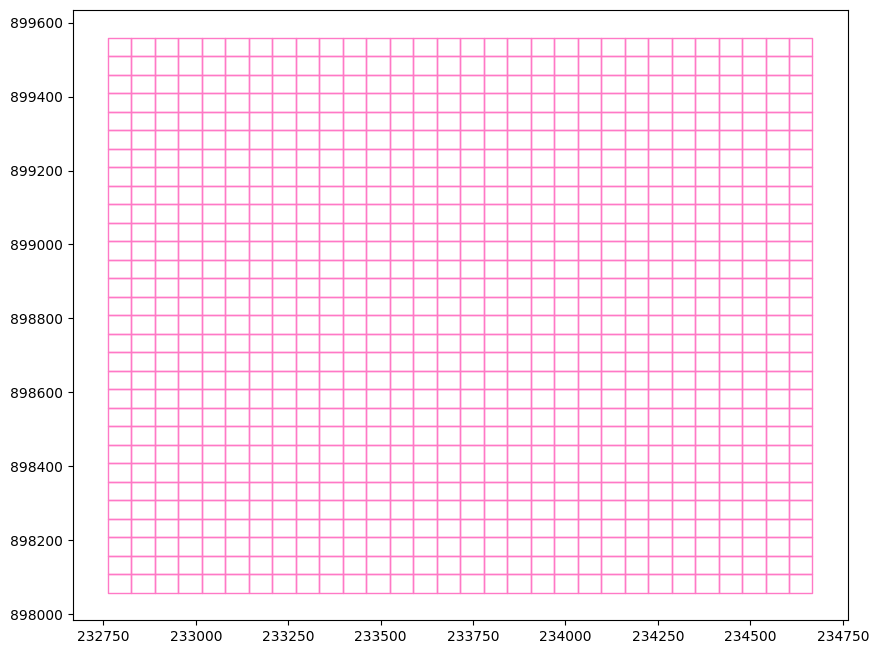

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

PATH_GRID = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/spatial/grid_rectangles.geojson")

grid = gpd.read_file(PATH_GRID)

print(f"cells: {len(grid)}")
print(f"crs: {grid.crs}")
print(f"columns: {list(grid.columns)}")
print(f"bounds: {grid.total_bounds}")

fig, ax = plt.subplots(figsize = (10, 10))
grid.plot(ax = ax, facecolor = "none", edgecolor = "#FF79C6", linewidth = 1)
ax.set_aspect("equal")
plt.show()

## Cell 2: Open the two EPA sensor locations and store them in two variables location_roxbury = [] location_(the other one) = []


In [2]:
import pandas as pd

EPA_SENSOR_DATA_PATH = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_26_sensor_comparisons/data/boston_pm25_combined.csv")

ROXBURY_KEY = "DUDLEY SQUARE ROXBURY"
VON_HILLERN_KEY = "VON HILLERN ST"

epa_data = pd.read_csv(EPA_SENSOR_DATA_PATH)

sub_data_roxbury = epa_data[epa_data["site_name"] == ROXBURY_KEY]
location_roxbury = [list(sub_data_roxbury["lon"])[0], list(sub_data_roxbury["lat"])[0]]

sub_data_von_hillern = epa_data[epa_data["site_name"] == VON_HILLERN_KEY]
location_von_hillern = [list(sub_data_von_hillern["lon"])[0], list(sub_data_von_hillern["lat"])[0]]

print(f"{ROXBURY_KEY}: {location_roxbury}")
print(f"{VON_HILLERN_KEY}: {location_von_hillern}")

DUDLEY SQUARE ROXBURY: [-71.0826, 42.3295]
VON HILLERN ST: [-71.056061, 42.325186]


## Cell 3: calculate how many squares we need to add in x and how many in y to enclose those positions starting from the initial grid.


In [3]:
import numpy as np
from shapely.geometry import Point

first_cell_bounds = grid.geometry.iloc[0].bounds
cell_width = first_cell_bounds[2] - first_cell_bounds[0]
cell_height = first_cell_bounds[3] - first_cell_bounds[1]

minimum_x, minimum_y, maximum_x, maximum_y = grid.total_bounds

epa_locations = {
    ROXBURY_KEY: location_roxbury,
    VON_HILLERN_KEY: location_von_hillern
}

epa_points = gpd.GeoSeries(
    [Point(location[0], location[1]) for location in epa_locations.values()],
    crs = "EPSG:4326"
).to_crs(grid.crs)

print(f"cell size: {cell_width:.2f} m in x, {cell_height:.2f} m in y")
print(f"grid x: {minimum_x:.2f} to {maximum_x:.2f}   grid y: {minimum_y:.2f} to {maximum_y:.2f}")
print()

for site_name, point in zip(epa_locations, epa_points):
    print(f"{site_name}: x = {point.x:.2f}, y = {point.y:.2f}")

columns_to_add_left = int(np.ceil(max(0.0, minimum_x - epa_points.x.min())/cell_width))
columns_to_add_right = int(np.ceil(max(0.0, epa_points.x.max() - maximum_x)/cell_width))
rows_to_add_below = int(np.ceil(max(0.0, minimum_y - epa_points.y.min())/cell_height))
rows_to_add_above = int(np.ceil(max(0.0, epa_points.y.max() - maximum_y)/cell_height))

print()
print(f"columns to add on the left (-x):  {columns_to_add_left}")
print(f"columns to add on the right (+x): {columns_to_add_right}")
print(f"rows to add below (-y):           {rows_to_add_below}")
print(f"rows to add above (+y):           {rows_to_add_above}")

cell size: 63.52 m in x, 50.03 m in y
grid x: 232762.53 to 234668.07   grid y: 898058.69 to 899559.50

DUDLEY SQUARE ROXBURY: x = 234401.66, y = 897751.92
VON HILLERN ST: x = 236591.45, y = 897283.79

columns to add on the left (-x):  0
columns to add on the right (+x): 31
rows to add below (-y):           16
rows to add above (+y):           0


## Cell 4: Create that extended grid with the cells added and save it under a folder of the same name of the folder where the notebook is located but in data.


extended grid: 61 columns x 46 rows = 2806 cells
cells inheriting an id from the original grid: 900 of 900
new cells: 1906
DUDLEY SQUARE ROXBURY inside the extended grid: True
VON HILLERN ST inside the extended grid: True
saved /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_09_17_create_epa_vectors_for_inference/grid_rectangles_extended.geojson


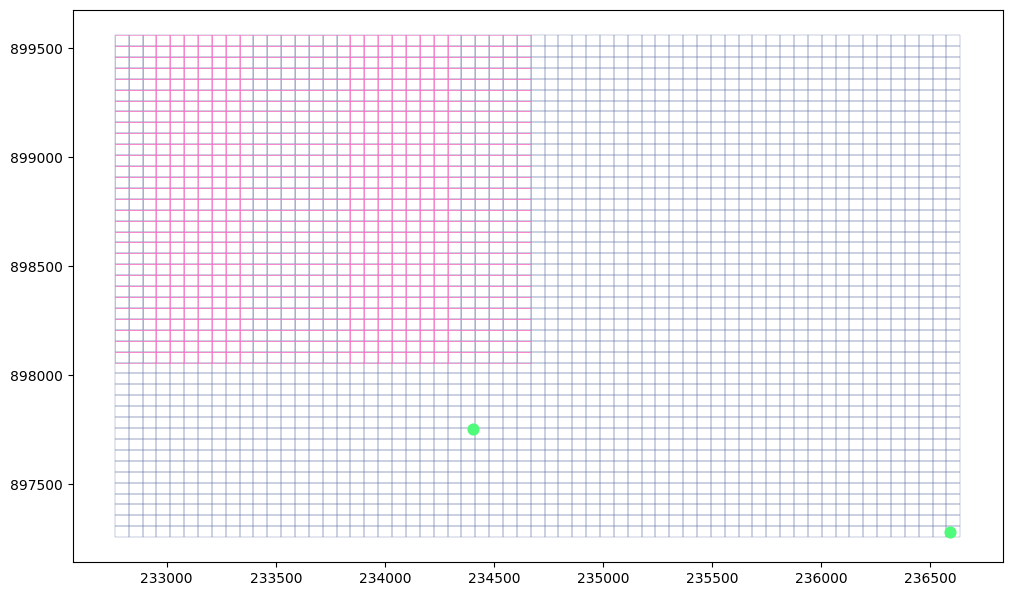

In [4]:
from shapely.geometry import box

NOTEBOOK_FOLDER_NAME = "2026_09_17_create_epa_vectors_for_inference"
PARENT_PATH_DATA = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data")/NOTEBOOK_FOLDER_NAME
PARENT_PATH_DATA.mkdir(parents = True, exist_ok = True)

extended_minimum_x = minimum_x - columns_to_add_left*cell_width
extended_maximum_x = maximum_x + columns_to_add_right*cell_width
extended_minimum_y = minimum_y - rows_to_add_below*cell_height
extended_maximum_y = maximum_y + rows_to_add_above*cell_height

n_columns = int(round((extended_maximum_x - extended_minimum_x)/cell_width))
n_rows = int(round((extended_maximum_y - extended_minimum_y)/cell_height))

rectangles = []
for row_index in range(n_rows):
    for column_index in range(n_columns):
        left = extended_minimum_x + column_index*cell_width
        bottom = extended_minimum_y + row_index*cell_height
        rectangles.append(box(left, bottom, left + cell_width, bottom + cell_height))

extended_grid = gpd.GeoDataFrame(geometry = rectangles, crs = grid.crs)

centroids = extended_grid.copy()
centroids["geometry"] = extended_grid.geometry.centroid
matched = gpd.sjoin(centroids, grid[["id", "geometry"]], how = "left", predicate = "within")
matched = matched[~matched.index.duplicated(keep = "first")]

extended_grid["id"] = matched["id"].to_numpy()
n_inherited = int(extended_grid["id"].notna().sum())

next_id = int(grid["id"].max()) + 1
new_ids = extended_grid["id"].isna()
extended_grid.loc[new_ids, "id"] = range(next_id, next_id + int(new_ids.sum()))
extended_grid["id"] = extended_grid["id"].astype(int)
extended_grid = extended_grid[["id", "geometry"]]

print(f"extended grid: {n_columns} columns x {n_rows} rows = {len(extended_grid)} cells")
print(f"cells inheriting an id from the original grid: {n_inherited} of {len(grid)}")
print(f"new cells: {int(new_ids.sum())}")

epa_inside = [extended_grid.geometry.union_all().contains(point) for point in epa_points]
for site_name, inside in zip(epa_locations, epa_inside):
    print(f"{site_name} inside the extended grid: {inside}")

PATH_EXTENDED_GRID = PARENT_PATH_DATA/"grid_rectangles_extended.geojson"
extended_grid.to_file(PATH_EXTENDED_GRID, driver = "GeoJSON")
print(f"saved {PATH_EXTENDED_GRID}")

fig, ax = plt.subplots(figsize = (12, 12))
extended_grid.plot(ax = ax, facecolor = "none", edgecolor = "#6272A4", linewidth = 0.25)
grid.plot(ax = ax, facecolor = "none", edgecolor = "#FF79C6", linewidth = 0.4)
epa_points.plot(ax = ax, color = "#50FA7B", markersize = 60, zorder = 3)
ax.set_aspect("equal")
plt.show()

## Cell 5: Compute all the satellite features we need to run the inference models

We already have extractors that retrieve the rasters and average them over the grid cells. The
features you need to get are `ndvi`, `ndbi` `imperivous` `road_density`.

Each extractor is called with the extended grid, so the values land on the same cells as the
original grid where the two footprints overlap. Parameters follow
`notebooks/kriging_layers/extraction.ipynb`. Results are written to
`data/2026_09_17_create_epa_vectors_for_inference/<feature_name>.geojson`.

`tiger_road_density_extractor.py` imports its base class as `from data_extract import ...`
instead of `from .data_extract import ...`, so `src/data_extraction` has to be on `sys.path`
as well as the project root. The same applies to the census, emissions and tree canopy
extractors.


In [5]:
import sys

PROJECT_ROOT = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis")
PATH_DATA_EXTRACTION = PROJECT_ROOT/"src"/"data_extraction"

for path in (PROJECT_ROOT, PATH_DATA_EXTRACTION):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from src.data_extraction.ndvi_extractor import NDVIExtractor
from src.data_extraction.ndbi_extractor import NDBIExtractor
from src.data_extraction.nlcd_impervious_extractor import NLCDImperviousExtractor
from src.data_extraction.tiger_road_density_extractor import TIGERRoadDensityExtractor

DATE_RANGE = "2025-05-01/2025-09-30"
MAX_CLOUD_COVER = 20.0
NDVI_MAX_ITEMS = 24
NDBI_MAX_ITEMS = 30

IMPERVIOUS_YEAR = 2024
IMPERVIOUS_REGION = "CU"
IMPERVIOUS_COLLECTION = 1
IMPERVIOUS_VERSION = 1
IMPERVIOUS_LOCAL_PATH = str(PROJECT_ROOT/"data"/"kriging_satellite"/"nlcd"/"Annual_NLCD_FctImp_2024_CU_C1V1.zip")

TIGER_YEAR = 2024
TIGER_STATE_FIPS = "25"
TIGER_COUNTY_FIPS = "025"

extended_bbox = tuple(float(value) for value in extended_grid.total_bounds)
print(f"bbox: {extended_bbox}")

satellite_extractors = {
    "ndvi": NDVIExtractor(
        datetime_range = DATE_RANGE,
        max_cloud_cover = MAX_CLOUD_COVER,
        max_items = NDVI_MAX_ITEMS,
        grid_path = PATH_EXTENDED_GRID
    ),
    "ndbi": NDBIExtractor(
        datetime_range = DATE_RANGE,
        max_cloud_cover = MAX_CLOUD_COVER,
        max_items = NDBI_MAX_ITEMS,
        grid_path = PATH_EXTENDED_GRID
    ),
    "impervious": NLCDImperviousExtractor(
        year = IMPERVIOUS_YEAR,
        region = IMPERVIOUS_REGION,
        collection = IMPERVIOUS_COLLECTION,
        version = IMPERVIOUS_VERSION,
        local_raster_path = IMPERVIOUS_LOCAL_PATH,
        grid_path = PATH_EXTENDED_GRID
    ),
    "road_density": TIGERRoadDensityExtractor(
        year = TIGER_YEAR,
        state_fips = TIGER_STATE_FIPS,
        county_fips = TIGER_COUNTY_FIPS,
        local_roads_path = None,
        grid_path = PATH_EXTENDED_GRID
    )
}

satellite_grids = {}
for feature_name, extractor in satellite_extractors.items():
    feature_grid = extractor.extract_for_grid(extended_bbox, grid = extended_grid)
    satellite_grids[feature_name] = feature_grid

    output_path = PARENT_PATH_DATA/f"{feature_name}.geojson"
    feature_grid.to_file(output_path, driver = "GeoJSON")

    value_columns = [c for c in extractor.value_columns if c in feature_grid.columns]
    filled = {c: int(feature_grid[c].notna().sum()) for c in value_columns}
    print(f"{feature_name}: {len(feature_grid)} cells, non-null {filled} -> {output_path.name}")

bbox: (232762.5266563353, 897258.2532420958, 236637.13623386374, 899559.4952891566)
ndvi: 2806 cells, non-null {'ndvi': 2806} -> ndvi.geojson
ndbi: 2806 cells, non-null {'ndbi': 2806} -> ndbi.geojson
impervious: 2806 cells, non-null {'impervious': 2806} -> impervious.geojson
road_density: 2806 cells, non-null {'road_density_km_km2': 2382, 'major_road_density_km_km2': 238} -> road_density.geojson


In [7]:
feature_grid.head()

,id,geometry,road_density_km_km2,major_road_density_km_km2
0,900,"POLYGON ((232826.045 897258.253, 232826.045 89...",20.088165,NaN
1,901,"POLYGON ((232889.563 897258.253, 232889.563 89...",31.566312,NaN
2,902,"POLYGON ((232953.081 897258.253, 232953.081 89...",34.446676,NaN
3,903,"POLYGON ((233016.599 897258.253, 233016.599 89...",32.911543,NaN
4,904,"POLYGON ((233080.118 897258.253, 233080.118 89...",3.411474,NaN


<Axes: >

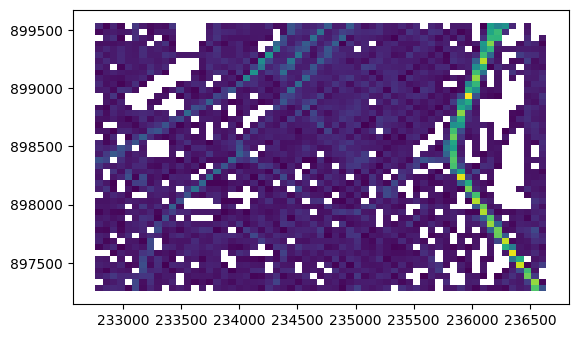

In [8]:
feature_grid.plot("road_density_km_km2")

<Axes: >

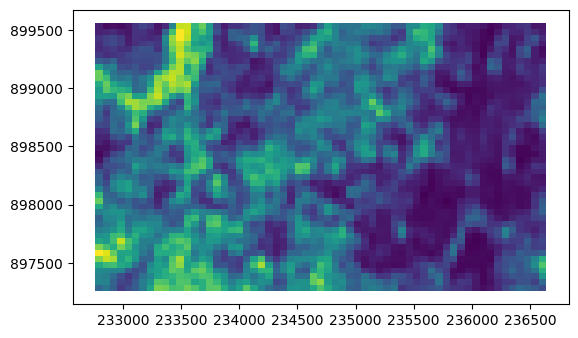

In [11]:
satellite_grids["ndvi"].plot("ndvi")